# 2 · Confronto tra i picchi
Si fittano i tempi residui con la somma di due esponenziali convolute con una gaussiana.
Per ogni anello: $\Delta t=t_{picco}-t_{picco,rif}$; il riferimento unisce gli anelli con **−0,2 ≤ cos θ < 0,2**.
L’estrazione di questa parte usa il ToF rettilineo con indice efficace **1,59**.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

dati = Path("dati")
plt.rcParams.update({"font.size": 11, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 120})

import json
from scipy.stats import exponnorm

esempio = json.loads((dati / "fit_14383.json").read_text())
istogrammi = np.loadtxt(dati / "istogrammi_14383.csv", delimiter=",", skiprows=1)
run_z = np.loadtxt("../dati_comuni/run_calibrazione.txt")[:, :2]
delta = np.loadtxt(dati / "delta_doubleexpgauss.txt")
assert delta.shape == (len(run_z), 40)

### Un anello e il riferimento
Run 14383, sorgente a z = 17,1 m. Le due distribuzioni sono normalizzate all’area: nessun fattore di riscalamento arbitrario. Le curve usano i parametri del fit originale.

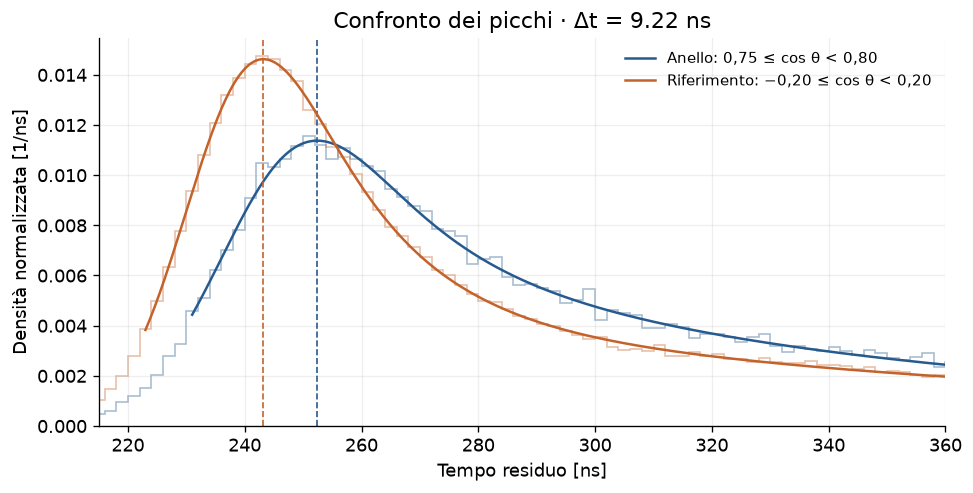

In [2]:
def modello(t, parametri):
    C1, mu, sigma, tau1, C2, tau2, fondo = parametri
    return (C1 * exponnorm.pdf(t, tau1 / sigma, loc=mu, scale=sigma)
            + C2 * exponnorm.pdf(t, tau2 / sigma, loc=mu, scale=sigma) + fondo)

edges = np.r_[istogrammi[:, 0], istogrammi[-1, 1]]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for col, fit, colore in zip([2, 3], esempio["fit"], ["#275a8e", "#c3632b"]):
    counts = istogrammi[:, col]
    area = np.sum(counts * np.diff(edges))
    t = np.linspace(fit["fit_min_ns"], fit["fit_max_ns"], 800)
    ax.stairs(counts / area, edges, color=colore, alpha=.4)
    ax.plot(t, modello(t, fit["parametri"]) / area, color=colore, label=fit["nome"])
    ax.axvline(fit["picco_ns"], color=colore, ls="--", lw=1)
differenza = esempio["fit"][0]["picco_ns"] - esempio["fit"][1]["picco_ns"]
ax.set(xlabel="Tempo residuo [ns]", ylabel="Densità normalizzata [1/ns]",
       title=f"Confronto dei picchi · Δt = {differenza:.2f} ns", xlim=(215, 360))
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=.2)
plt.show()

### Mappa radiale
Per $r>0$ si mediano i punti a $+z$ e $-z$, invertendo l’asse angolare del lato negativo. Si mostra il quadrante $\cos\theta>0$; a r = 0 si conserva la riga originale.

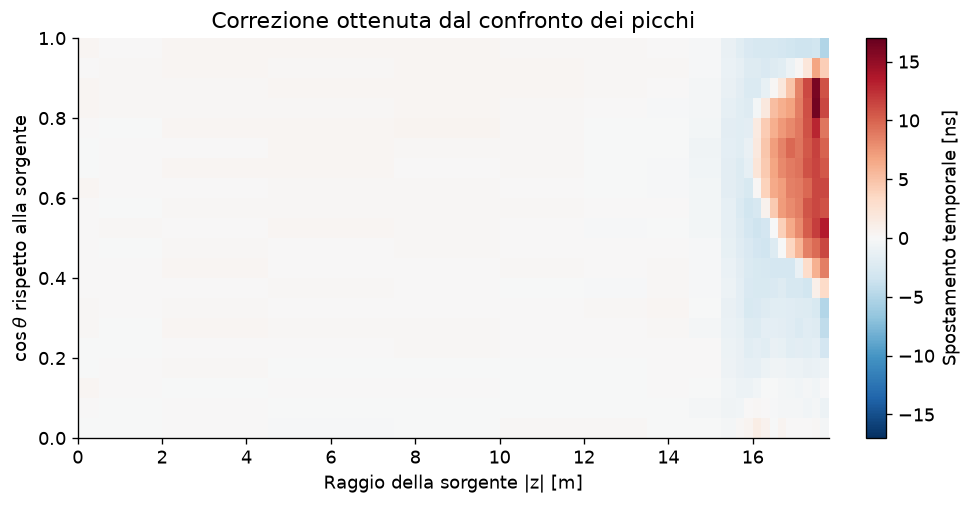

In [3]:
per_z = dict(zip(run_z[:, 1], delta))
raggi = np.unique(np.abs(run_z[:, 1]))
mappa = []
for r in raggi:
    lati = [per_z[r]] if r in per_z else []
    if -r in per_z and r != 0:
        lati.append(per_z[-r][::-1])
    mappa.append(np.mean(lati, axis=0)[20:])
mappa = np.array(mappa)
r_bordi = np.r_[0, (raggi[:-1] + raggi[1:]) / 2,
                raggi[-1] + (raggi[-1] - raggi[-2]) / 2] / 1000
limite = np.ceil(np.max(np.abs(mappa)))
fig, ax = plt.subplots(figsize=(8, 4.1), layout="constrained")
im = ax.pcolormesh(r_bordi, np.linspace(0, 1, 21), mappa.T,
                   cmap="RdBu_r", vmin=-limite, vmax=limite)
ax.set(xlabel="Raggio della sorgente |z| [m]", ylabel=r"$\cos\theta$ rispetto alla sorgente",
       title="Correzione ottenuta dal confronto dei picchi")
fig.colorbar(im, ax=ax, label="Spostamento temporale [ns]")
plt.show()

Il confronto dell’esempio dà **Δt ≈ 9,22 ns**. Le righe a **17,5 e 17,7 m** provengono solo dal lato positivo; una correzione positiva va sottratta ai residui.